# WasteWise — Model Comparison

This notebook compares MobileNetV3-Small, ResNet18, and EfficientNet-B0 using results from the same 378 validation images. Macro-F1 is the main comparison measure, along with performance by material and processing time.

A follow-up experiment examines whether class-weighted training improves EfficientNet-B0. All results come from completed experiments; no models were retrained or evaluated on the test set in this notebook.


## 1. Saved Experiments

The completed five-epoch run for each model was loaded and checked against the same dataset split and class labels. This provides a consistent basis for comparing their results.


In [1]:
from pathlib import Path
import os
import sys

# Set this only if the repository has moved and automatic discovery cannot find it.
ROOT_OVERRIDE = None
explicit_root = ROOT_OVERRIDE or os.environ.get("WASTEWISE_ROOT")
start = Path.cwd().resolve()
candidates = ([Path(explicit_root).expanduser()] if explicit_root else
              [start, *start.parents, Path.home() / "Projects" / "WasteWise"])
for candidate in candidates:
    candidate = candidate.resolve()
    if ((candidate / "src/experiment_data.py").is_file()
            and (candidate / "manifests/split_manifest.csv").is_file()):
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Set ROOT_OVERRIDE to the WasteWise project root and rerun this cell.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src import experiment_data as datasets
from src import experiment_results as results

if Path(datasets.__file__).resolve().parent.parent != PROJECT_ROOT:
    raise RuntimeError("A different WasteWise checkout is cached. Restart this kernel.")
print("Project root: .")
print("Python interpreter:", Path(sys.executable).name)
display(results.package_table())

Project root: .
Python interpreter: python


,Version
Package,
torch,2.14.1
torchvision,0.29.1
numpy,2.5.3
pandas,3.0.6
Pillow,12.3.0
matplotlib,3.11.2
ipykernel,7.4.0


In [2]:
data = datasets.load_experiment_data(PROJECT_ROOT)
RUN_NAMES = {
    "mobilenetv3_small": "baseline_seed42_5epochs",
    "resnet18": "baseline_seed42_5epochs",
    "efficientnet_b0": "baseline_seed42_5epochs",
}
runs = []
status = []
for model_name in results.MODEL_NAMES:
    directory = results.run_path(PROJECT_ROOT, model_name, RUN_NAMES[model_name])
    if not (directory / "complete.json").is_file():
        state = "Incomplete" if directory.exists() else "Not yet run"
    else:
        # Invalid completed files raise an error rather than silently entering the comparison.
        runs.append(results.load_run(PROJECT_ROOT, model_name, RUN_NAMES[model_name], data))
        state = "Completed and records verified"
    status.append({"Model": model_name, "Run": RUN_NAMES[model_name], "Status": state})
display(pd.DataFrame(status).set_index("Model"))
all_complete = len(runs) == len(results.MODEL_NAMES)
comparison = results.comparison_table(runs) if runs else pd.DataFrame()
if not comparison.empty:
    display(comparison.set_index("Model").round(4))
if not all_complete:
    print("Comparison and ranking remain pending until all three real baselines are complete.")

,Run,Status
Model,,
mobilenetv3_small,baseline_seed42_5epochs,Completed and records verified
resnet18,baseline_seed42_5epochs,Completed and records verified
efficientnet_b0,baseline_seed42_5epochs,Completed and records verified


,Macro-F1,Accuracy,Weighted F1,Validation images,Best epoch,Trainable parameters,Training seconds,Device,Forward median ms,End-to-end median ms
Model,,,,,,,,,,
EfficientNet-B0,0.8722,0.8915,0.8917,378,5,7686,53.7225,mps,4.5119,6.4432
ResNet18,0.8044,0.8333,0.8316,378,5,3078,34.5441,mps,2.7305,4.8583
MobileNetV3-Small,0.7759,0.8148,0.8126,378,4,3462,26.7106,mps,2.9955,4.6602


## 2. Validation Performance

Macro-F1 was used as the main measure because it gives equal importance to all six categories, including the smaller trash category. Accuracy and F1 for each material were also compared. The reported results come from the best validation epoch of each five-epoch run.

EfficientNet-B0 achieved the highest macro-F1 (0.8722), followed by ResNet18 (0.8044) and MobileNetV3-Small (0.7759). The detailed table also reports precision, recall, and the number of images in each category.


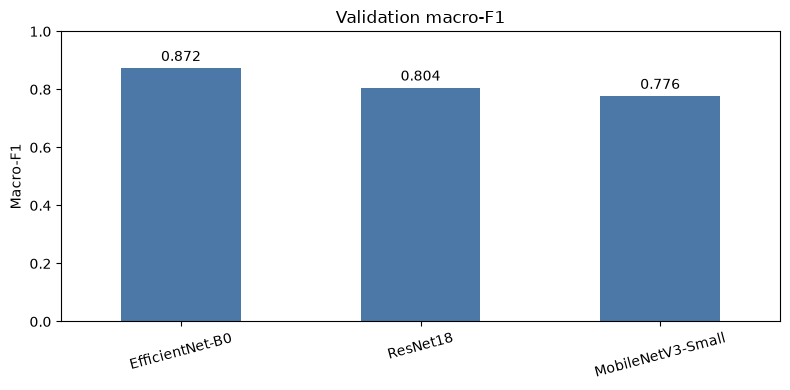

,MobileNetV3-Small,ResNet18,EfficientNet-B0
class,,,
cardboard,0.8527,0.9231,0.8852
glass,0.8212,0.8052,0.8933
metal,0.8455,0.8000,0.9206
paper,0.8333,0.8901,0.9133
plastic,0.8029,0.7972,0.8889
trash,0.5000,0.6111,0.7317


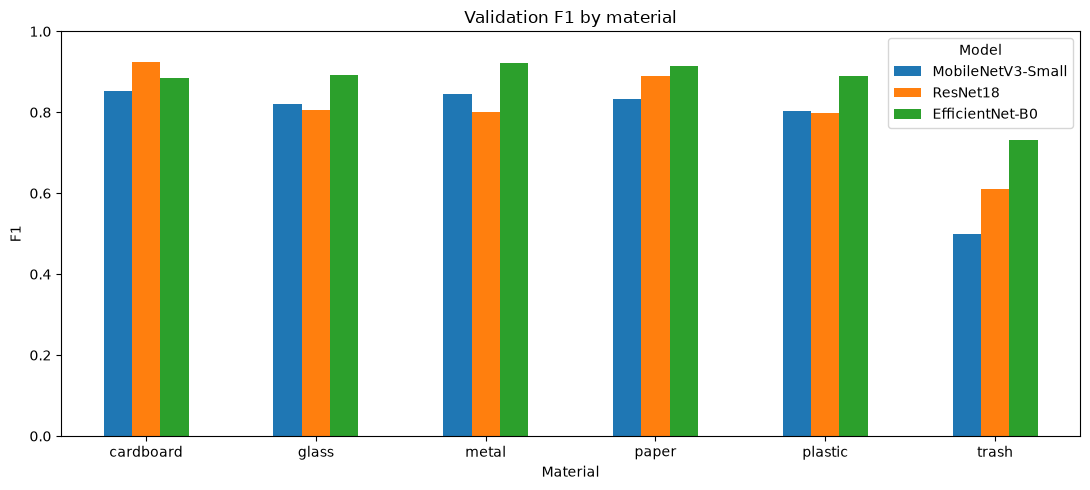

precision  recall      f1  support
Model             Category                                     
MobileNetV3-Small cardboard     0.8088  0.9016  0.8527       61
                  glass         0.8158  0.8267  0.8212       75
                  metal         0.8387  0.8525  0.8455       61
                  paper         0.8242  0.8427  0.8333       89
                  plastic       0.8462  0.7639  0.8029       72
                  trash         0.5625  0.4500  0.5000       20
ResNet18          cardboard     0.9643  0.8852  0.9231       61
                  glass         0.7848  0.8267  0.8052       75
                  metal         0.8519  0.7541  0.8000       61
                  paper         0.8333  0.9551  0.8901       89
                  plastic       0.8028  0.7917  0.7972       72
                  trash         0.6875  0.5500  0.6111       20
EfficientNet-B0   cardboard     0.8852  0.8852  0.8852       61
                  glass         0.8933  0.8933  0.8933       75
                  metal         0.8923  0.9508  0.9206       61
                  paper         0.9405  0.8876  0.9133       89
                  plastic       0.8889  0.8889  0.8889       72
                  trash         0.7143  0.7500  0.7317       20

In [3]:
if all_complete:
    ordered = comparison.set_index("Model")
    fig, ax = plt.subplots(figsize=(8, 4))
    ordered["Macro-F1"].plot.bar(ax=ax, color="#4c78a8", rot=15)
    ax.set(title="Validation macro-F1", ylabel="Macro-F1", ylim=(0, 1), xlabel="")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3)
    fig.tight_layout()
    plt.show()

    class_f1 = pd.DataFrame({
        run["config"]["display_name"]: pd.DataFrame(run["metrics"]["per_class"]).set_index("class")["f1"]
        for run in runs
    }).reindex(data["classes"])
    display(class_f1.round(4))
    ax = class_f1.plot.bar(figsize=(11, 5), rot=0)
    ax.set(title="Validation F1 by material", ylabel="F1", ylim=(0, 1), xlabel="Material")
    ax.legend(title="Model")
    plt.tight_layout()
    plt.show()

    per_class = pd.concat([
        pd.DataFrame(run["metrics"]["per_class"])
        .assign(Model=run["config"]["display_name"])
        for run in runs
    ], ignore_index=True)
    display(per_class.set_index(["Model", "class"])[
        ["precision", "recall", "f1", "support"]
    ].rename_axis(index=["Model", "Category"]).round(4))

## 3. Confusion Matrices

The confusion matrices show where the three models made incorrect predictions on the same 378 validation images. Rows represent the actual categories, and columns represent the predicted categories.


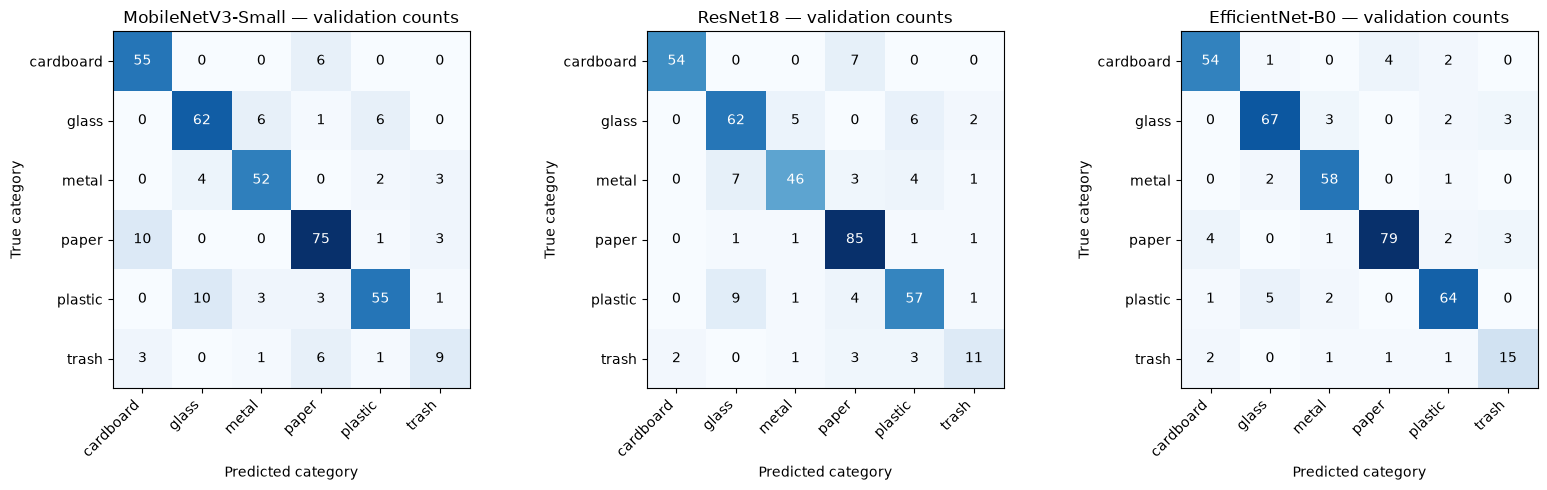

In [4]:
if all_complete:
    fig, axes = plt.subplots(1, 3, figsize=(19, 5))
    for run, ax in zip(runs, axes):
        results.plot_confusion(run, ax=ax)
    fig.tight_layout()
    plt.show()

## 4. Training and Prediction Time

All three models were measured on the same local device. MobileNetV3-Small had the shortest training time (26.71 seconds), while EfficientNet-B0 took the longest (53.72 seconds).

The end-to-end measurements include image preparation and prediction. They describe local model performance rather than the response time of the complete WasteWise application.


In [5]:
if all_complete:
    display(comparison[["Model", "Device", "Trainable parameters", "Training seconds",
                        "Forward median ms", "End-to-end median ms"]].set_index("Model").round(3))
    measurement_context = pd.DataFrame([{
        "Model": run["config"]["display_name"],
        "Device": run["config"]["device"], "Platform": run["config"]["platform"],
        "PyTorch": run["config"]["package_versions"]["torch"],
        "Torchvision": run["config"]["package_versions"]["torchvision"],
        "CPU threads": run["config"]["cpu_threads"],
    } for run in runs]).set_index("Model")
    display(measurement_context)
    if measurement_context.drop_duplicates().shape[0] != 1:
        print("Measurement environments differ. Treat timing differences cautiously.")

,Device,Trainable parameters,Training seconds,Forward median ms,End-to-end median ms
Model,,,,,
EfficientNet-B0,mps,7686,53.722,4.512,6.443
ResNet18,mps,3078,34.544,2.730,4.858
MobileNetV3-Small,mps,3462,26.711,2.995,4.660


,Device,Platform,PyTorch,Torchvision,CPU threads
Model,,,,,
MobileNetV3-Small,mps,macOS-26.6.2-arm64-arm-64bit-Mach-O,2.14.1,0.29.1,4
ResNet18,mps,macOS-26.6.2-arm64-arm-64bit-Mach-O,2.14.1,0.29.1,4
EfficientNet-B0,mps,macOS-26.6.2-arm64-arm-64bit-Mach-O,2.14.1,0.29.1,4


## 5. Classification Errors

Predictions for the same validation images were compared to identify mistakes shared across models. The tables summarize common category confusions, and the images show examples of errors from the leading baseline, EfficientNet-B0.

These examples help illustrate classification difficulties but do not establish the cause of each error.


MobileNetV3-Small


,true_label,predicted_label,Images
0,plastic,glass,10
1,paper,cardboard,10
2,cardboard,paper,6
3,trash,paper,6
4,glass,plastic,6


ResNet18


,true_label,predicted_label,Images
0,plastic,glass,9
1,cardboard,paper,7
2,metal,glass,7
3,glass,plastic,6
4,glass,metal,5


EfficientNet-B0


,true_label,predicted_label,Images
0,plastic,glass,5
1,paper,cardboard,4
2,cardboard,paper,4
3,glass,metal,3
4,glass,trash,3


,True label,MobileNetV3-Small,ResNet18,EfficientNet-B0,Models incorrect
path,,,,,
trash/trash80.jpg,trash,plastic,plastic,metal,3
glass/glass288.jpg,glass,plastic,plastic,plastic,3
paper/paper228.jpg,paper,trash,metal,metal,3
metal/metal18.jpg,metal,plastic,glass,glass,3
metal/metal172.jpg,metal,plastic,plastic,plastic,3
glass/glass443.jpg,glass,metal,metal,metal,3
plastic/plastic370.jpg,plastic,glass,glass,glass,3
plastic/plastic467.jpg,plastic,metal,metal,metal,3
metal/metal45.jpg,metal,glass,glass,glass,3


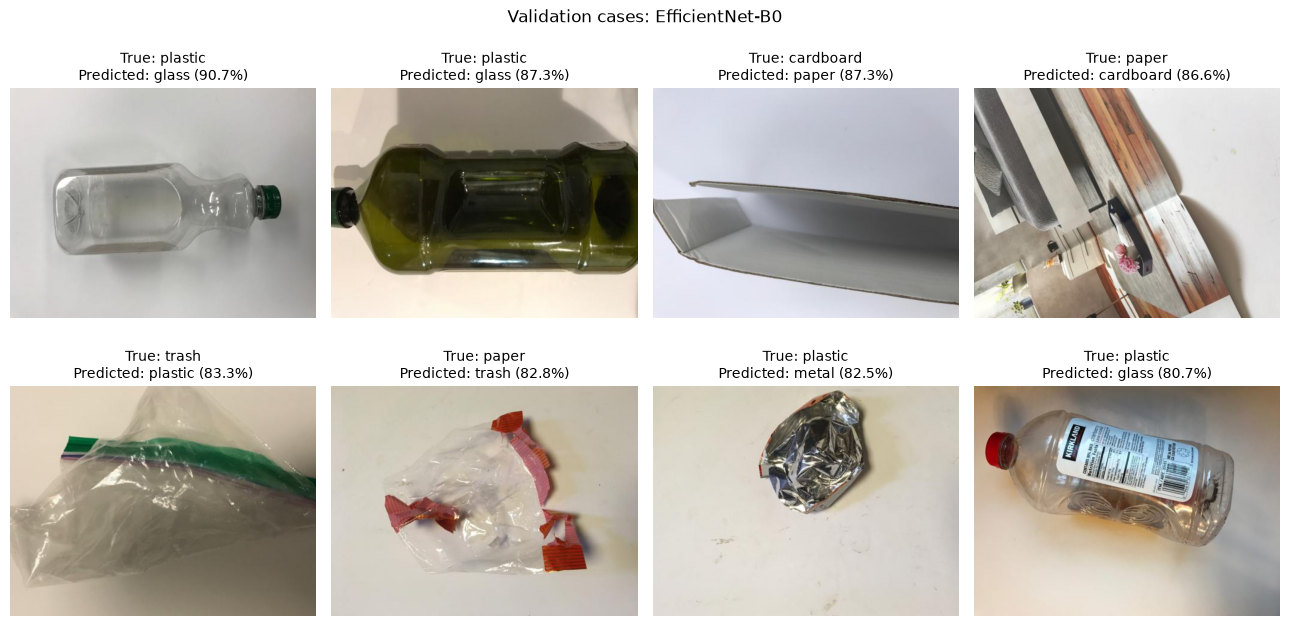

In [6]:
if all_complete:
    joined = data["validation"][["path", "label"]].set_index("path").rename(columns={"label": "True label"})
    wrong_count = pd.Series(0, index=joined.index)
    for run in runs:
        predictions = run["predictions"].set_index("path")
        joined[run["config"]["display_name"]] = predictions["predicted_label"]
        wrong_count += (~predictions["correct"]).reindex(joined.index).astype(int)
        print(run["config"]["display_name"])
        display(results.confusion_pairs(run))
    joined["Models incorrect"] = wrong_count
    display(joined.loc[wrong_count > 0].sort_values("Models incorrect", ascending=False).head(10))
    leading_run = max(runs, key=lambda run: run["metrics"]["macro_f1"])
    examples = results.prediction_examples(leading_run, correct=False, limit=8)
    results.plot_predictions(data, examples, f"Validation cases: {leading_run['config']['display_name']}")
    plt.show()

## 6. Baseline Model Selection

EfficientNet-B0 achieved the highest validation macro-F1 (0.8722) and the highest F1 in five of the six categories. ResNet18 performed best on cardboard.

Although EfficientNet-B0 required more training and prediction time, its overall validation performance made it the initial candidate for WasteWise. The test set was not used for this decision.


In [7]:
if all_complete:
    best_score = comparison["Macro-F1"].max()
    leaders = comparison.loc[(comparison["Macro-F1"] - best_score).abs() <= 1e-12, "Model"]
    if len(leaders) == 1:
        display(Markdown(
            f"**Leading baseline: {leaders.iloc[0]}**, validation macro-F1 "
            f"**{best_score:.4f}** on {len(data['validation'])} images."
        ))
    else:
        display(Markdown("**Macro-F1 tie:** " + ", ".join(leaders) + ". Review class performance and cost."))

    efficient_run = next(run for run in runs if run["config"]["model_name"] == "efficientnet_b0")
    efficient_metrics = pd.DataFrame(efficient_run["metrics"]["per_class"]).set_index("class")
    weakest = efficient_metrics["f1"].idxmin()
    trash = efficient_metrics.loc["trash"]
    predictions = efficient_run["predictions"]
    true_trash = predictions["true_label"].eq("trash")
    predicted_trash = predictions["predicted_label"].eq("trash")
    display(Markdown(
        f"EfficientNet-B0's lowest class F1 is **{weakest} "
        f"({efficient_metrics.loc[weakest, 'f1']:.4f})**. For trash, precision is "
        f"{trash['precision']:.4f}, recall {trash['recall']:.4f}, and F1 {trash['f1']:.4f}, "
        f"with {int(trash['support'])} validation examples. "
        f"There are {int((true_trash & predicted_trash).sum())} correct trash predictions, "
        f"{int((true_trash & ~predicted_trash).sum())} missed trash examples, and "
        f"{int((~true_trash & predicted_trash).sum())} other images predicted as trash. "
        f"One additional correct trash prediction changes recall by "
        f"{100 / trash['support']:.0f} percentage points, so small differences need cautious interpretation."
    ))
    class_leaders = class_f1.apply(lambda row: ", ".join(row.index[row.eq(row.max())]), axis=1)
    display(pd.DataFrame({"Highest baseline F1": class_f1.max(axis=1),
                          "Leading model(s)": class_leaders}).rename_axis("Category").round(4))
else:
    print("Candidate selection requires all three completed baseline runs.")

**Leading baseline: EfficientNet-B0**, validation macro-F1 **0.8722** on 378 images.

EfficientNet-B0's lowest class F1 is **trash (0.7317)**. For trash, precision is 0.7143, recall 0.7500, and F1 0.7317, with 20 validation examples. There are 15 correct trash predictions, 5 missed trash examples, and 6 other images predicted as trash. One additional correct trash prediction changes recall by 5 percentage points, so small differences need cautious interpretation.

,Highest baseline F1,Leading model(s)
Category,,
cardboard,0.9231,ResNet18
glass,0.8933,EfficientNet-B0
metal,0.9206,EfficientNet-B0
paper,0.9133,EfficientNet-B0
plastic,0.8889,EfficientNet-B0
trash,0.7317,EfficientNet-B0


## 7. Weighted-Loss Experiment

A second EfficientNet-B0 run tested whether giving more weight to smaller categories during training would improve performance. Only the training loss was changed. Both runs used the same pretrained weights, dataset split, preprocessing, frozen feature layers, seed (42), Adam optimizer (0.001), batch size (32), and five training epochs.

The two versions were compared on the same 378 validation images. In the table, each change is calculated as the weighted result minus the original result.


In [8]:
from src import weighted_experiment as weighted

baseline_efficient = results.load_run(PROJECT_ROOT, "efficientnet_b0", "baseline_seed42_5epochs", data)
weighted_run = weighted.load_weighted_run(data, baseline_efficient)
loss_comparison = weighted.comparison_table(data, baseline_efficient, weighted_run).T
loss_comparison["Change (weighted − baseline)"] = (
    loss_comparison["Weighted cross-entropy"] - loss_comparison["Unweighted baseline"])
display(loss_comparison.round(4))
assert baseline_efficient["metrics"]["latency"]["sample_paths"] == weighted_run["metrics"]["latency"]["sample_paths"]
print("Verified: identical validation paths and labels, split checksum, controlled settings, and latency sample.")

Configuration,Unweighted baseline,Weighted cross-entropy,Change (weighted − baseline)
Macro-F1,0.8722,0.8485,-0.0237
Accuracy,0.8915,0.8730,-0.0185
Weighted F1,0.8917,0.8755,-0.0162
Trash precision,0.7143,0.5714,-0.1429
Trash recall,0.7500,0.8000,0.0500
Trash F1,0.7317,0.6667,-0.0650
Validation loss (unweighted),0.3619,0.4256,0.0637
Validation images,378.0000,378.0000,0.0000
Best epoch,5.0000,3.0000,-2.0000
Training seconds,53.7225,54.6284,0.9059


Verified: identical validation paths and labels, split checksum, controlled settings, and latency sample.


### Results by Category

The table compares F1 scores for each material. The confusion matrices show the actual and predicted categories for both versions of EfficientNet-B0, using the same color scale.


,Validation images,Baseline F1,Weighted F1,F1 change
Category,,,,
cardboard,61,0.8852,0.8760,-0.0092
glass,75,0.8933,0.8831,-0.0102
metal,61,0.9206,0.8800,-0.0406
paper,89,0.9133,0.9240,0.0107
plastic,72,0.8889,0.8613,-0.0276
trash,20,0.7317,0.6667,-0.0650


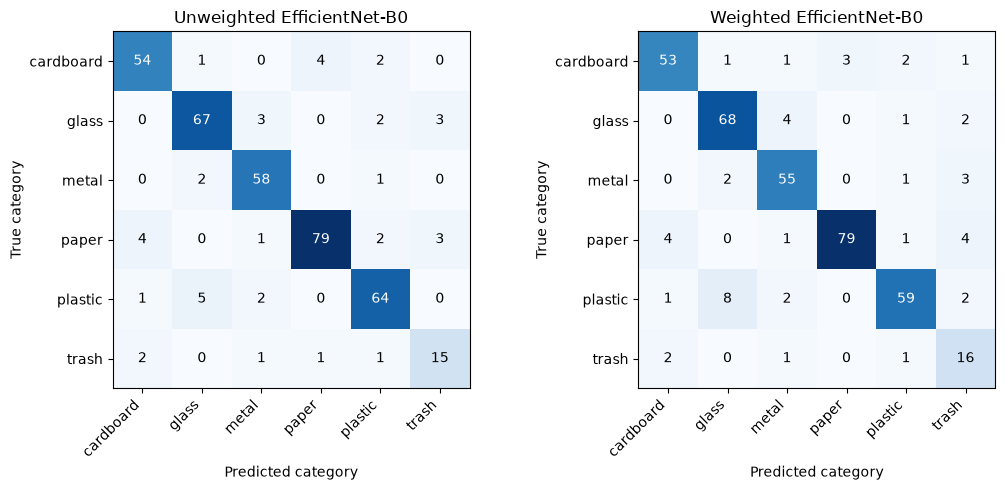

In [9]:
baseline_classes = pd.DataFrame(baseline_efficient["metrics"]["per_class"]).set_index("class")
weighted_classes = pd.DataFrame(weighted_run["metrics"]["per_class"]).set_index("class")
loss_class_f1 = pd.DataFrame({
    "Validation images": baseline_classes["support"],
    "Baseline F1": baseline_classes["f1"],
    "Weighted F1": weighted_classes["f1"],
}).reindex(data["classes"])
loss_class_f1["F1 change"] = loss_class_f1["Weighted F1"] - loss_class_f1["Baseline F1"]
display(loss_class_f1.rename_axis("Category").round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
maximum = max(max(map(max, item["metrics"]["confusion_matrix"])) for item in [baseline_efficient, weighted_run])
for ax, title, item in zip(axes, ["Unweighted EfficientNet-B0", "Weighted EfficientNet-B0"],
                           [baseline_efficient, weighted_run]):
    results.plot_confusion(item, ax=ax)
    ax.set_title(title)
    ax.images[0].set_clim(0, maximum)
fig.tight_layout()
plt.show()

### Confident Errors

The table shows six incorrect predictions that received scores of at least 80% from the weighted model. It also shows how the original model classified those same images. A high score does not guarantee a correct prediction.


In [10]:
weighted_predictions = weighted_run["predictions"]
confident_errors = weighted_predictions.loc[
    ~weighted_predictions["correct"] & weighted_predictions["confidence"].ge(0.80)
].sort_values(["confidence", "path"], ascending=[False, True])
error_comparison = confident_errors[["path", "true_label", "predicted_label", "confidence"]].merge(
    baseline_efficient["predictions"][["path", "predicted_label", "confidence"]],
    on="path", suffixes=("_weighted", "_baseline"), validate="one_to_one")
display(error_comparison.set_index("path").round(4))
paired_outcomes = baseline_efficient["predictions"][["path", "correct"]].merge(
    weighted_predictions[["path", "correct"]], on="path", suffixes=("_baseline", "_weighted"), validate="one_to_one")
display(pd.Series({
    "Baseline errors corrected": int((~paired_outcomes["correct_baseline"] & paired_outcomes["correct_weighted"]).sum()),
    "New errors after weighting": int((paired_outcomes["correct_baseline"] & ~paired_outcomes["correct_weighted"]).sum()),
}, name="Validation images").to_frame())

,true_label,predicted_label_weighted,confidence_weighted,predicted_label_baseline,confidence_baseline
path,,,,,
plastic/plastic95.jpg,plastic,glass,0.9595,glass,0.8730
plastic/plastic94.jpg,plastic,glass,0.9186,glass,0.9070
plastic/plastic370.jpg,plastic,glass,0.8521,glass,0.7952
plastic/plastic69.jpg,plastic,glass,0.8473,glass,0.8074
paper/paper590.jpg,paper,trash,0.8257,trash,0.8276
cardboard/cardboard392.jpg,cardboard,paper,0.8073,paper,0.8726


,Validation images
Baseline errors corrected,3
New errors after weighting,10


## Conclusion

EfficientNet-B0 was the strongest baseline, with a validation macro-F1 of **0.8722** and accuracy of **89.15%**. MobileNetV3-Small trained fastest, while ResNet18 achieved the highest F1 for cardboard.

The weighted-loss experiment did not improve EfficientNet-B0. Macro-F1 decreased from **0.8722 to 0.8485**, and accuracy decreased from **89.15% to 87.30%**. For trash, recall increased from 0.75 to 0.80, but precision fell from 0.7143 to 0.5714 because more images from other categories were classified as trash. Trash F1 consequently decreased from 0.7317 to 0.6667. Paper F1 improved slightly, but the other five categories performed worse.

The weighted model corrected three mistakes from the baseline and introduced ten new errors. Six incorrect predictions received scores of at least 80% in the weighted run; all six were also errors in the baseline. Training and prediction times remained similar.

**The original EfficientNet-B0 baseline therefore remains the selected candidate** based on validation macro-F1. This decision is based on one random seed and one validation split, with only 20 trash images. Some related images may also remain unidentified. The test set was kept separate and still requires final evaluation.
